<a href="https://colab.research.google.com/github/asnapareeth004-hue/encoder_decoder/blob/main/DNN_Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**DNN Implementation**

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)
torch.manual_seed(0)

Using: cpu


In [ ]:
# ---------------- Data ----------------
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_ds = datasets.MNIST("./data", train=True, download=True, transform=tfm)
test_ds = datasets.MNIST("./data", train=False, download=True, transform=tfm)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=256)


100%|██████████| 9.91M/9.91M [00:00<00:00, 63.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.76MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.76MB/s]


In [ ]:
# ---------------- Model ----------------
class DNN(nn.Module):
    def __init__(self, in_dim=28 * 28, hidden=(512, 256, 128), n_classes=10, dropout=0.3):
        super().__init__()
        layers, prev = [nn.Flatten()], in_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, n_classes))  # raw logits (CrossEntropyLoss applies softmax)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


model = DNN().to(device)
print(model)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=5, gamma=0.5)

DNN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=512, out_features=256, bias=True)
    (6): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, out_features=128, bias=True)
    (10): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU()
    (12): Dropout(p=0.3, inplace=False)
    (13): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 569,226


In [ ]:
# ---------------- Train / evaluate ----------------
def evaluate(dl):
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total


history = {"train_loss": [], "test_loss": [], "test_acc": []}
EPOCHS = 10

for epoch in range(1, EPOCHS + 1):
    model.train()
    running, n = 0.0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        opt.zero_grad()
        loss.backward()
        opt.step()
        running += loss.item() * len(y)
        n += len(y)
    sched.step()

    test_loss, test_acc = evaluate(test_dl)
    history["train_loss"].append(running / n)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
    print(f"epoch {epoch:2d} | train loss {running / n:.4f} | test loss {test_loss:.4f} | test acc {test_acc:.4f}")

epoch  1 | train loss 0.1145 | test loss 0.0709 | test acc 0.9785
epoch  2 | train loss 0.0957 | test loss 0.0701 | test acc 0.9780
epoch  3 | train loss 0.0822 | test loss 0.0605 | test acc 0.9813
epoch  4 | train loss 0.0717 | test loss 0.0597 | test acc 0.9802
epoch  5 | train loss 0.0510 | test loss 0.0531 | test acc 0.9841
epoch  6 | train loss 0.0443 | test loss 0.0496 | test acc 0.9851
epoch  7 | train loss 0.0420 | test loss 0.0490 | test acc 0.9848
epoch  8 | train loss 0.0364 | test loss 0.0525 | test acc 0.9842
epoch  9 | train loss 0.0354 | test loss 0.0548 | test acc 0.9848
epoch 10 | train loss 0.0292 | test loss 0.0490 | test acc 0.9856


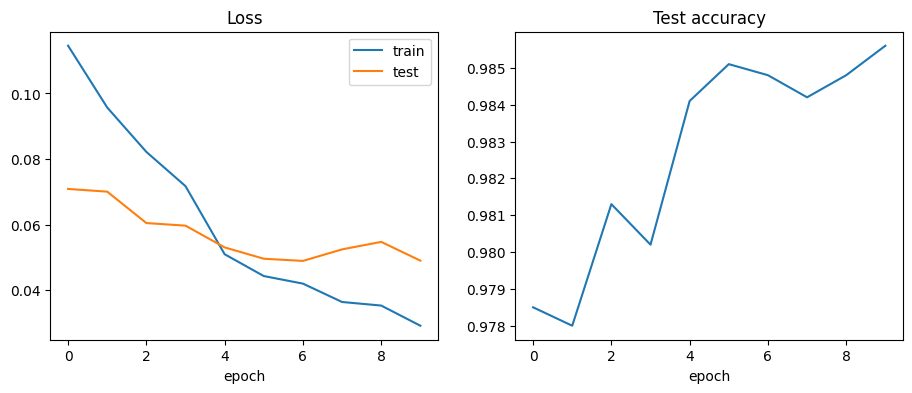

In [ ]:
# ---------------- Plots ----------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["test_loss"], label="test")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["test_acc"])
ax[1].set_title("Test accuracy"); ax[1].set_xlabel("epoch")
plt.show()

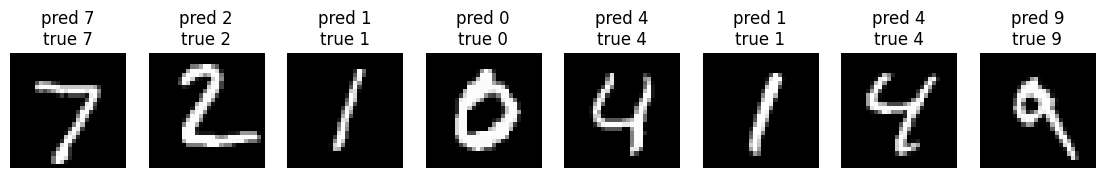

In [ ]:
# ---------------- Sample predictions ----------------
model.eval()
x, y = next(iter(test_dl))
with torch.no_grad():
    pred = model(x.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(1, 8, figsize=(14, 2.5))
for i, a in enumerate(axes):
    a.imshow(x[i].squeeze(), cmap="gray")
    a.set_title(f"pred {pred[i].item()}\ntrue {y[i].item()}")
    a.axis("off")
plt.show()